# ODE synthetic data: threshold TLS → balanced sampling → tsfresh → distance distributions

This notebook pairs with `solve_ivp_synthetic.py` in the same directory; it does not depend on labeling or logging modules from other directories.
By default it writes separate **4-class and 5-class** datasets with exactly 10,000 samples per class and a 90% train/validation, 10% test split.
The 4-class set uses only the cycle pool without k4; the 5-class set reuses the same S1–S4 samples and adds S5 from the k4 pool.
4-class and 5-class are independent tasks; sharing S1–S4 samples and splits is intentional.

## 0. Generate raw pools first

Run in this directory. Raw pool size is not the per-class sample count; threshold pass rates can be low.

```bash
python solve_ivp_synthetic.py --class_num 4 --job_num 600000 --num_proc 24 --seed 42 --log_interval 10000
python solve_ivp_synthetic.py --class_num 5 --job_num 400000 --num_proc 24 --seed 42 --log_interval 10000
# If a class is short, add independent samples to the SAME raw directory:
python solve_ivp_synthetic.py --class_num 4 --job_num 600000 --num_proc 24 --seed 43 --log_interval 10000
```

The generator uses one fully reversible cycle topology (all five cycle rate constants independently nonzero), not per-class zero masks;
it only checks solver validity, conservation, and fast/slow observability. Default `mass_mode=strict` includes Step 3 substrate consumption.
This notebook applies the archived `label_cycle_data.py` threshold rules, **not a pure-TLS partition**;
it does not claim to auto-reproduce older models or match every wording in the response letter.

Runtime: numpy / scipy / pandas / sklearn / tsfresh / pycatch22 / matplotlib / seaborn;
you can use an existing `my_org_mech` kernel. Full feature extraction takes a while—check sample coverage before continuing.

Output layout:
```text
data/
  ode_raw_data/4_class/*.json
  ode_raw_data/5_class/*.json
  4_class/{train_val,test,train_val_tsfresh_feat,test_tsfresh_feat}.csv
  5_class/{train_val,test,train_val_tsfresh_feat,test_tsfresh_feat}.csv
```
Each raw file holds one trajectory. No seed/run/audit directories are created.
Running all preparation cells replaces the four named CSVs in each selected output directory.
The generator keeps one generation.log per raw directory; notebook summaries remain in cell outputs.


In [ ]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import logging
import math
import random
import sys
import time

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from sklearn.model_selection import train_test_split
from tsfresh import extract_features
from tsfresh.feature_extraction.settings import ComprehensiveFCParameters
from tsfresh.feature_extraction.feature_calculators import set_property
import pycatch22
import matplotlib.pyplot as plt
import seaborn as sns

# Launch from the project root or its parent; otherwise set PROJECT_ROOT manually.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'solve_ivp_synthetic.py').is_file():
    PROJECT_ROOT = PROJECT_ROOT / 'Classification_of_Substrate_Orders_in_Reaction_Kinetics'
if not (PROJECT_ROOT / 'solve_ivp_synthetic.py').is_file():
    raise FileNotFoundError('Set PROJECT_ROOT to the directory that contains solve_ivp_synthetic.py')

DATA_ROOT = PROJECT_ROOT / 'data'
RAW_ROOT = DATA_ROOT / 'ode_raw_data'
CYCLE_POOL_ROOTS = [RAW_ROOT / '4_class']
SIDE_POOL_ROOTS = [RAW_ROOT / '5_class']
CLASS_NUMS = [4, 5]                 # may be [4] or [5]
SAMPLE_SIZE = 10000
TEST_FRACTION = 0.1
RANDOM_SEED = 42
N_JOBS = 24
FEATURE_BATCH_SIZE = 2000
LOG_INTERVAL = 20000               # raw trajectory count
OUTPUT_ROOT = DATA_ROOT
EXPECTED_MASS_MODE = 'strict'

# TLS criteria: keep archived threshold rules; distinguish detection floor from turnover-metric bounds.
TLS = dict(delta_min=0.005, k_max=10.0, alpha_ab=0.1,
           rho_fast=0.005, rev_tol=0.005, eta_max=1.0)
S_DETECT = 0.05
# eta_max=1 means k4 <= [Cat]tot*k1*k2/(km1+k2).
# If the final written definition is "side reaction below 1% of the catalytic rate", set this to 0.01 and regenerate.
EPS_CHOICES = (0.0, 0.005, 0.01, 0.02)  # absolute-concentration Gaussian sigma; unrelated to TLS thresholds
SCOLS = [f's{i}' for i in range(30)]
PCOLS = [f'p{i}' for i in range(30)]
CURVE_COLS = SCOLS + PCOLS
CLASS_ORDER = ['S1', 'S2', 'S3', 'S4', 'S5']
COLORS = dict(zip(CLASS_ORDER, ['#FFA878', '#79A1E3', '#88D59A', '#E37275', '#AB9FD6']))
print('Project:', PROJECT_ROOT)
print('Output:', OUTPUT_ROOT)


## 1. Threshold rules and unique labels

Let `S0=1`, `Km=(km1+k2)/k1`, `theta4=(km2+k3*S0)/k2`:

| Class | Thresholds applied in this notebook |
|---|---|
| S1 | k2/(k1*S0) < rho_fast; k2/(k3*S0) < rho_fast; km1 <= rev_tol*k2 |
| S2 | delta_min < Km/S0 < k_max; k2/(k3*S0) < rho_fast; km2 <= rev_tol*k2 |
| S3 | k1*S0/k2 < alpha_ab; k1/k3 < rho_fast |
| S4 | delta_min < theta4 < k_max; k3/k1 < rho_fast |
| S5 | In the k4 pool, the cycle thresholds uniquely hit S2 and 0 < eta <= eta_max |

Here `eta=k4/([Cat]tot*k1*k2/(km1+k2))`; terminal side-product fraction phi is not used.
The no-k4 pool keeps only trajectories that hit **exactly one** of S1–S4; the k4 pool contributes only S5.
Hitting S2 and S5 together is not treated as a label conflict: first assign a unique main-cycle label, then check the side-reaction condition.

`[0.05*S0,S0]` is the detection window; `[delta_min,k_max]` is the turnover-metric range—they are not the same interval.
For example, the S1 fast-step ratio at S=0.05*S0 is at most 0.005/0.05=0.1.
Threshold-style S2/S4 **does not guarantee** that the raw crossing k2/k1 or k2/k3 lies inside the detection window.
The in-memory sampling map records the crossing and whether it falls in the window; this is not an extra filter.
These defaults must not be read as a threshold-free pure-TLS definition; S3's two separation ratios are kept as in the table above.

Raw pools are left intact. Counts of accepted, conflicting, and unlabeled samples are shown in the notebook.


In [ ]:
def validate_config():
    if not CLASS_NUMS or len(set(CLASS_NUMS)) != len(CLASS_NUMS) or not set(CLASS_NUMS) <= {4, 5}:
        raise ValueError('CLASS_NUMS must be [4], [5], or [4, 5]')
    if SAMPLE_SIZE < 2 or not 0 < TEST_FRACTION < 1:
        raise ValueError('Invalid sample size or test fraction')
    if not 0 < TLS['delta_min'] < TLS['k_max']:
        raise ValueError('delta_min must be less than k_max')
    if any(not np.isfinite(v) or v <= 0 for v in TLS.values()):
        raise ValueError('TLS parameters must be finite and positive')
    if any(not np.isfinite(v) or v < 0 for v in EPS_CHOICES) or not EPS_CHOICES:
        raise ValueError('EPS_CHOICES must be non-negative finite numbers')
    if any(v <= 0 for v in (N_JOBS, FEATURE_BATCH_SIZE, LOG_INTERVAL)):
        raise ValueError('Parallelism and batch/block sizes must be positive')
    if EXPECTED_MASS_MODE not in ('strict', 'legacy'):
        raise ValueError('Invalid EXPECTED_MASS_MODE')


def threshold_hits(d, thresholds=TLS):
    k1, km1, k2, km2, k3 = [float(d[k]) for k in ('k1','km1','k2','km2','k3')]
    s0 = float(d['s0'])
    delta, kmax, alpha, fast, rev = [thresholds[k] for k in
                                    ('delta_min','k_max','alpha_ab','rho_fast','rev_tol')]
    km = (km1 + k2) / (k1 * s0)
    theta4 = (km2 + k3 * s0) / k2
    hits = []
    if k2/(k1*s0) < fast and k2/(k3*s0) < fast and km1 <= rev*k2:
        hits.append('S1')
    if delta < km < kmax and k2/(k3*s0) < fast and km2 <= rev*k2:
        hits.append('S2')
    if k1*s0/k2 < alpha and k1/k3 < fast:
        hits.append('S3')
    if delta < theta4 < kmax and k3/k1 < fast:
        hits.append('S4')
    return hits


def label_record(d, kind, thresholds=TLS):
    hits = threshold_hits(d, thresholds)
    kcat = d['cat0'] * d['k1'] * d['k2'] / (d['km1'] + d['k2'])
    eta = d['k4'] / kcat
    s_cross = d['k2'] / min(d['k1'], d['k3'])
    metadata = dict(cycle_hits='|'.join(hits), eta=eta, s_cross=s_cross,
                    cross_in_detection_window=S_DETECT*d['s0'] < s_cross < d['s0'])
    if len(hits) != 1:
        return None, ('unlabelled' if not hits else 'ambiguous_cycle'), metadata
    if kind == 'cycle':
        return hits[0], 'eligible', metadata
    if hits[0] != 'S2':
        return None, 'side_cycle_not_S2', metadata
    if not 0 < eta <= thresholds['eta_max']:
        return None, 'side_eta_outside', metadata
    return 'S5', 'eligible', metadata


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()


def discover_json_files(roots):
    files = []
    for root in roots:
        root = Path(root).resolve()
        if not root.is_dir():
            raise FileNotFoundError(f'Raw pool directory does not exist: {root}')
        found = sorted(root.glob('*.json'))
        if not found:
            raise FileNotFoundError(f'No raw JSON files found: {root}')
        files.extend(p.resolve() for p in found)
    if len(files) != len(set(files)):
        raise ValueError('Overlapping raw-pool paths; the same JSON cannot be read twice')
    return sorted(files)


def validate_record(d, kind):
    if d.get('schema') != 'cosork-unified-ode-v1' or d.get('pool_kind') != kind:
        raise ValueError('Raw pool schema/kind mismatch; use the paired generator')
    if d.get('mass_mode') != EXPECTED_MASS_MODE:
        raise ValueError('Raw pool mass-conservation mode mismatch; cannot mix strict/legacy')
    if d.get('s0') != 1.0 or not np.isclose(d.get('cat0', 0), 0.01):
        raise ValueError('This notebook fixes S0=1 and cat0/S0=0.01')
    rates = np.array([d[k] for k in ('k1','km1','k2','km2','k3','k4')], dtype=float)
    if not np.isfinite(rates).all() or (rates[:5] <= 0).any():
        raise ValueError('Invalid rate constants')
    if (kind == 'cycle' and rates[-1] != 0) or (kind == 'side' and rates[-1] <= 0):
        raise ValueError('k4 inconsistent with raw pool kind')
    if not isinstance(d.get('raw_id'), str) or not d['raw_id']:
        raise ValueError('Missing stable raw_id')
    t = np.asarray(d['t'], dtype=float)
    z = np.asarray([d[k] for k in ('s','p','cat','cats','catsp','bp')], dtype=float)
    if z.shape != (6,30) or t.shape != (30,) or not np.isfinite(z).all() or not np.isfinite(t).all():
        raise ValueError('Each trajectory needs 30 finite concentration/time points')
    if not np.allclose(t, np.linspace(0,180,30), rtol=0, atol=1e-8):
        raise ValueError('This pipeline fixes 180 s with 30 equally spaced points')
    if z.min() < -1e-6:
        raise ValueError('Negative concentration exceeds tolerance')
    p_factor = 2 if EXPECTED_MASS_MODE == 'strict' else 1
    if not np.allclose(z[2:5].sum(axis=0), 0.01, rtol=0, atol=5e-6):
        raise ValueError('Catalyst conservation check failed')
    if not np.allclose(z[0]+p_factor*z[1]+z[3]+z[4]+z[5], 1, rtol=0, atol=5e-6):
        raise ValueError('Substrate-equivalent conservation check failed')
    if not (z[0,19] > 0.05 and 0 < z[0,29] < 0.5):
        raise ValueError('Trajectory fails the shared fast/slow observability requirement')


def scan_and_sample(files_by_kind):
    # Uniform reservoir sampling without replacement; retain only selected rows.
    labels = CLASS_ORDER if 5 in CLASS_NUMS else CLASS_ORDER[:4]
    reservoirs = {c: [] for c in labels}
    eligible = Counter()
    rngs = {c: random.Random(f'tls-reservoir:{RANDOM_SEED}:{c}') for c in labels}
    counts = Counter()
    seen = set()
    started = time.monotonic()
    for kind, files in files_by_kind.items():
        for path in files:
            try:
                with path.open() as f:
                    d = json.load(f)
                validate_record(d, kind)
            except Exception as exc:
                raise ValueError(f'{path}: {exc}') from exc
            rid = d['raw_id']
            if rid in seen:
                raise ValueError(f'Duplicate raw trajectory: {rid}')
            seen.add(rid)
            label, reason, meta = label_record(d, kind)
            counts[f'{kind}:{reason}'] += 1
            if label is not None:
                eligible[label] += 1
                n = eligible[label]
                j = n-1 if n <= SAMPLE_SIZE else rngs[label].randrange(n)
                if j < SAMPLE_SIZE:
                    row = dict(id=f'{label}-{rid}', **{'class':label},
                               raw_id=rid, source_file=str(path), pool_kind=kind, **meta)
                    row.update(zip(CURVE_COLS, d['s'] + d['p']))
                    if n <= SAMPLE_SIZE:
                        reservoirs[label].append(row)
                    else:
                        reservoirs[label][j] = row
            if len(seen) % LOG_INTERVAL == 0:
                LOGGER.info('read=%d elapsed=%.1fs eligible=%s',
                            len(seen), time.monotonic()-started, dict(eligible))
    return reservoirs, dict(total=len(seen), counts=dict(counts), eligible=dict(eligible))


## 2. Read JSON pools and sample each class

Independent reservoir sampling per class, without replacement and with a fixed seed.
Files are read in sorted order; only selected samples are kept in memory.
All classes must have at least SAMPLE_SIZE eligible trajectories before any training CSV is written.
If a class is short, add raw samples and rerun. Filtering counts and shortages are displayed here.


In [ ]:
validate_config()
files_by_kind = {'cycle': discover_json_files(CYCLE_POOL_ROOTS)}
if 5 in CLASS_NUMS:
    files_by_kind['side'] = discover_json_files(SIDE_POOL_ROOTS)
LOGGER = logging.getLogger('tls-prep')
LOGGER.setLevel(logging.INFO)
LOGGER.propagate = False
for old_handler in LOGGER.handlers[:]:
    LOGGER.removeHandler(old_handler)
    old_handler.close()
handler = logging.StreamHandler(sys.stdout)
handler.setFormatter(logging.Formatter('%(asctime)s %(message)s'))
LOGGER.addHandler(handler)

reservoirs, filter_summary = scan_and_sample(files_by_kind)
required_classes = CLASS_ORDER if 5 in CLASS_NUMS else CLASS_ORDER[:4]
shortages = {c: SAMPLE_SIZE-filter_summary['eligible'].get(c,0)
             for c in required_classes if filter_summary['eligible'].get(c,0) < SAMPLE_SIZE}
filter_summary['shortages'] = shortages
display(pd.DataFrame({'eligible':[filter_summary['eligible'].get(c,0) for c in required_classes],
                      'required':SAMPLE_SIZE}, index=required_classes))
print(filter_summary)
if shortages:
    raise RuntimeError(f'Each class needs {SAMPLE_SIZE} independent samples; shortages={shortages}. Top up the raw pools.')


## 3. Stratified split, measurement noise, and four training files

Split 90/10 by per-class raw trajectory ID first, then add measurement noise; each raw trajectory gets exactly one noisy version.
So that identical S1–S4 samples match bit-for-bit between 4-class and 5-class, the noise RNG is determined by the master seed and raw_id,
independent of processing order and label. This RNG scheme does not reproduce the old notebook's row-wise random sequence.
Small post-noise negatives are not clipped, preserving the Gaussian measurement-noise model.

The in-memory DataFrame `sampling_map` includes source file, label, split, and sigma. No extra CSV is written.
Rate constants, TLS crossings, eta, pool kind, and split metadata are not training features.


In [ ]:
def add_measurement_noise(frame):
    result = frame[['id'] + CURVE_COLS + ['class']].copy()
    sigmas = []
    values = result[CURVE_COLS].to_numpy(dtype=float, copy=True)
    for i, rid in enumerate(frame['raw_id']):
        seed = int.from_bytes(hashlib.sha256(f'tls-noise:{RANDOM_SEED}:{rid}'.encode()).digest()[:16], 'big')
        rng = random.Random(seed)
        sigma = rng.choice(EPS_CHOICES)
        values[i] += np.array([rng.gauss(0, sigma) for _ in CURVE_COLS])
        sigmas.append(sigma)
    result[CURVE_COLS] = values
    return result, sigmas


def assemble_datasets(reservoirs):
    by_class = {}
    mapping = []
    for c in required_classes:
        clean = pd.DataFrame(reservoirs[c]).sort_values('raw_id').reset_index(drop=True)
        if len(clean) != SAMPLE_SIZE or clean['raw_id'].duplicated().any():
            raise ValueError(f'{c} sample count or uniqueness check failed')
        train_idx, test_idx = train_test_split(np.arange(len(clean)), test_size=TEST_FRACTION,
                                             random_state=RANDOM_SEED, shuffle=True)
        split = np.full(len(clean), 'train_val', dtype=object)
        split[test_idx] = 'test'
        noisy, sigmas = add_measurement_noise(clean)
        by_class[c] = dict(train_val=noisy.iloc[train_idx].reset_index(drop=True),
                           test=noisy.iloc[test_idx].reset_index(drop=True))
        m = clean.drop(columns=CURVE_COLS).copy()
        m['split'] = split
        m['eps_sigma'] = sigmas
        mapping.append(m)
    sampling_map = pd.concat(mapping, ignore_index=True)
    datasets = {}
    for num in CLASS_NUMS:
        out = OUTPUT_ROOT/f'{num}_class'
        out.mkdir(parents=True, exist_ok=True)
        datasets[num] = {}
        for name in ('train_val','test'):
            df = pd.concat([by_class[c][name] for c in CLASS_ORDER[:num]], ignore_index=True)
            df = df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
            assert list(df.columns) == ['id'] + CURVE_COLS + ['class']
            assert df['id'].is_unique and np.isfinite(df[CURVE_COLS].to_numpy()).all()
            df.to_csv(out/f'{name}.csv', index=False)
            datasets[num][name] = df
        train, test = datasets[num]['train_val'], datasets[num]['test']
        assert not set(train['id']) & set(test['id'])
        counts = pd.concat([train,test])['class'].value_counts()
        assert counts.to_dict() == {c:SAMPLE_SIZE for c in CLASS_ORDER[:num]}
        LOGGER.info('%sc: train_val=%d test=%d; class totals=%s', num, len(train), len(test), counts.to_dict())
    return datasets, sampling_map


datasets, sampling_map = assemble_datasets(reservoirs)
# Later cells can read the output CSVs independently; sampled curve copies need not be kept.
del reservoirs


## 4. Extract tsfresh Comprehensive + catch22

Features are computed separately for the s and p time series. Batches reduce memory; n_jobs controls processes;
each batch logs progress and ETA. Non-finite stats from zero-variance series become NaN for later training,
without fitting an imputer on the full dataset. After extraction, rows are aligned to the original CSV ID order.

Four main files per class directory:
`train_val.csv`, `test.csv`, `train_val_tsfresh_feat.csv`, `test_tsfresh_feat.csv`.
Features are recomputed and replace the named output files; existing features are never silently reused.


In [ ]:
@set_property('fctype', 'combiner')
def catch22(x, param):
    data = pycatch22.catch22_all(x)
    return list(zip(data['names'], data['values']))


def extract_split_features(df, target, n_jobs=N_JOBS, batch_size=FEATURE_BATCH_SIZE):
    settings = ComprehensiveFCParameters()
    settings[catch22] = None
    started = time.monotonic()
    schema_cols = None
    nonfinite = 0
    partial = target.with_suffix('.csv.partial')
    for start in range(0, len(df), batch_size):
        block = df.iloc[start:start+batch_size]
        long = pd.DataFrame(dict(id=np.repeat(block['id'].to_numpy(),30),
                                 t=np.tile(np.arange(30),len(block)),
                                 s=block[SCOLS].to_numpy().ravel(),
                                 p=block[PCOLS].to_numpy().ravel()))
        features = extract_features(long, column_id='id', column_sort='t',
                                    default_fc_parameters=settings, n_jobs=n_jobs,
                                    disable_progressbar=True)
        assert features.index.is_unique and set(features.index) == set(block['id'])
        # Parallel workers may return feature columns in different orders.
        features = features.reindex(index=block['id'], columns=sorted(features.columns))
        assert all(c.startswith(('s__','p__')) for c in features.columns)
        nonfinite += int((~np.isfinite(features.to_numpy())).sum())
        features = features.replace([np.inf,-np.inf],np.nan)
        features.insert(0,'id',block['id'].to_numpy())
        features['class'] = block['class'].to_numpy()
        if schema_cols is None:
            schema_cols = list(features.columns)
            assert any('catch22' in c for c in schema_cols)
        if list(features.columns) != schema_cols:
            raise ValueError('Inconsistent column schema across feature-extraction batches')
        features.to_csv(partial, mode='w' if start == 0 else 'a', header=start == 0, index=False)
        done = start+len(block)
        elapsed = time.monotonic()-started
        LOGGER.info('%s %d/%d elapsed=%.1fs ETA=%.1fs', target.name, done,len(df),
                    elapsed, elapsed*(len(df)-done)/done)
    partial.replace(target)
    return dict(rows=len(df), columns=len(schema_cols), nonfinite_feature_values=nonfinite)


feature_summary = {}
for num in CLASS_NUMS:
    for name in ('train_val','test'):
        df = pd.read_csv(OUTPUT_ROOT/f'{num}_class'/f'{name}.csv', float_precision='round_trip')
        target = OUTPUT_ROOT/f'{num}_class'/f'{name}_tsfresh_feat.csv'
        feature_summary[f'{num}:{name}'] = extract_split_features(df, target)
display(pd.DataFrame(feature_summary).T)


## 5. Verify IDs, class counts, and output structure

Check that raw/feature tables match on id and class, train/test are disjoint, and per-class totals match the target.
Display SHA-256 and row counts for the four training CSVs. Every 4-class sample comes from the no-k4 pool.


In [ ]:
output_summary = {}
for num in CLASS_NUMS:
    out = OUTPUT_ROOT/f'{num}_class'
    output_summary[str(num)] = {}
    for name in ('train_val','test'):
        raw = pd.read_csv(out/f'{name}.csv', float_precision='round_trip')
        target = out/f'{name}_tsfresh_feat.csv'
        header = pd.read_csv(target, nrows=0).columns.tolist()
        assert all(c in ('id','class') or c.startswith(('s__','p__')) for c in header)
        feat_ids = pd.read_csv(target, usecols=['id','class'])
        pd.testing.assert_frame_equal(raw[['id','class']], feat_ids[['id','class']])
        for path in (out/f'{name}.csv',target):
            output_summary[str(num)][path.name] = dict(rows=len(raw), sha256=file_sha256(path),
                                                       bytes=path.stat().st_size)
    train = pd.read_csv(out/'train_val.csv', usecols=['id','class'])
    test = pd.read_csv(out/'test.csv', usecols=['id','class'])
    assert train.id.is_unique and test.id.is_unique and not set(train.id)&set(test.id)
    assert pd.concat([train,test])['class'].value_counts().to_dict() == {
        c:SAMPLE_SIZE for c in CLASS_ORDER[:num]}
    LOGGER.info('Verified %sc files: %s',num,list(output_summary[str(num)]))
print(json.dumps(output_summary,indent=2))
display(pd.DataFrame(feature_summary).T)


## 6. Euclidean distance distribution

Read the generated `data/5_class/train_val.csv` and `test.csv`.
For each test sample, compute the minimum Euclidean distance to any training sample
using the 60 noisy s/p concentration points, then show a boxplot grouped by true class.
This cell displays the figure only; it does not write distance CSVs or image files.


Computing distances for data/5_class


Computing distances: 100%|██████████| 5000/5000 [00:13<00:00, 378.04it/s]


,S1,S2,S3,S4,S5
0,0.131748,0.012672,0.009033,0.068413,0.129081
1,0.007238,0.034047,0.149201,0.036389,0.128528
2,0.069699,0.010475,0.153898,0.169481,0.046099
3,0.024029,0.081110,0.146683,0.048483,0.130637
4,0.170799,0.158663,0.000344,0.023963,0.086295


  S1: n=1000, mean=0.0660, median=0.0455
  S2: n=1000, mean=0.0673, median=0.0508
  S3: n=1000, mean=0.0694, median=0.0670
  S4: n=1000, mean=0.0694, median=0.0498
  S5: n=1000, mean=0.0882, median=0.0792


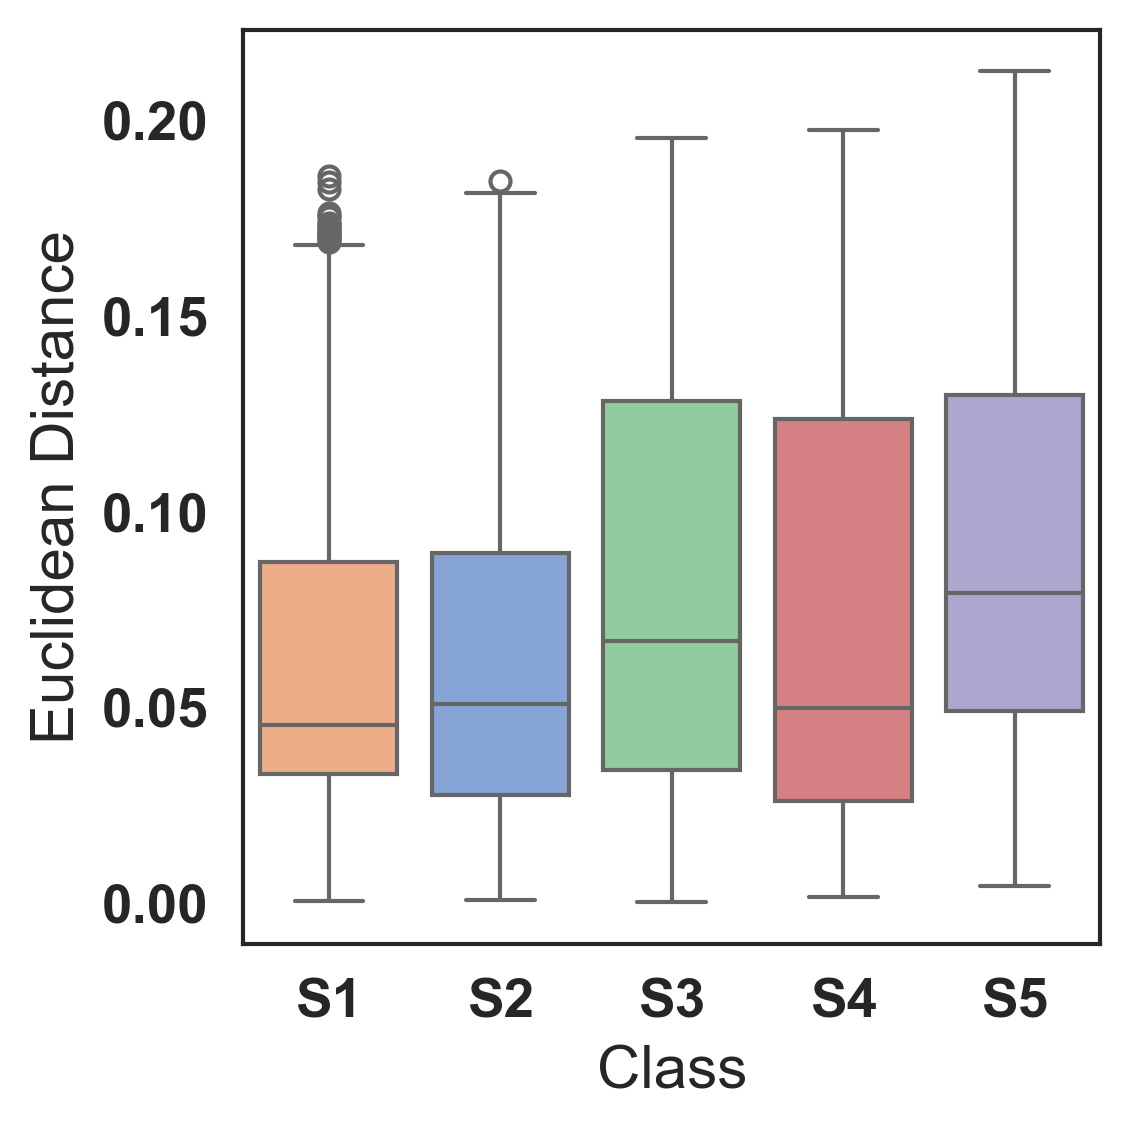

In [3]:
import os
from tqdm import tqdm
from scipy.spatial.distance import cdist
import seaborn as sns
from matplotlib import pyplot as plt

sns.set_theme(style='white')
sns.set_context('paper', font_scale=1.5)
plt.rcParams['font.family'] = 'Arial'

DATA_ROOT = 'data'

def compute_distances(train, test):
    """Min Euclidean distance of each test sample to any train sample, grouped by test class."""
    classes = sorted(train['class'].unique())
    distances = {cls: [] for cls in classes}
    train_feature = train.iloc[:, 1:-1].to_numpy(dtype=np.float64)

    for _, test_row in tqdm(test.iterrows(), total=len(test), desc='Computing distances'):
        cls = test_row['class']
        test_feature = np.asarray(test_row.values[1:-1], dtype=np.float64).reshape(1, -1)
        distance = cdist(train_feature, test_feature, metric='euclidean').min()
        distances[cls].append(distance)

    return distances


out_dir = os.path.join(DATA_ROOT, '5_class')
train_path = os.path.join(out_dir, 'train_val.csv')
test_path = os.path.join(out_dir, 'test.csv')
if not (os.path.exists(train_path) and os.path.exists(test_path)):
    raise FileNotFoundError(f'Missing train/test CSV under {out_dir}')

print(f'Computing distances for {out_dir}')
train_val_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)
distances = compute_distances(train_val_data, test_data)
distances_df = pd.DataFrame(distances)
distance_results = {
    '5_class': {
        'distances': distances,
        'distances_df': distances_df,
        'out_class_num': 5,
        'apparent_4class': False,
    }
}
display(distances_df.head())
for cls, vals in distances.items():
    print(f'  {cls}: n={len(vals)}, mean={np.mean(vals):.4f}, median={np.median(vals):.4f}')


colors_5_class = ['#FFA878', '#79A1E3', '#88D59A', '#E37275', '#AB9FD6']

distances_df = distance_results['5_class']['distances_df']
class_list = [c for c in ['S1', 'S2', 'S3', 'S4', 'S5'] if c in distances_df.columns]

plt.figure(figsize=(4, 4), dpi=300)
sns.boxplot(data=distances_df, order=class_list, palette=colors_5_class)
plt.ylabel('Euclidean Distance')
plt.xlabel('Class')
plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')
plt.tight_layout()
plt.show()

